# pose.dataset 개발 & 버그 픽스용 노트북

Data augmentation interface 추가된 버전

In [1]:
%load_ext autoreload
%autoreload 2

import os
import random
import sys
sys.path.append("/home/dev/pose")
sys.path.append("/home/dev/pose_v2/pose")

from pose.config import get_cfg_defaults

%matplotlib inline
import math
import torch

from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import InterpolationMode
from torchvision.transforms.v2 import ToPILImage
from torchvision.transforms.v2.functional import affine

from torchvision.utils import draw_bounding_boxes
from torchvision.utils import draw_keypoints

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

cfg = get_cfg_defaults()

connectivity = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
                [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
                [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]

kp_labels = ['nose', 'L-eye', 'R-eye', 'L-ear', 'R-ear',
             'L-shder', 'R-shder', 'L-elb', 'R-elb',
             'L-wrst', 'R-wrst', 'L-hip', 'R-hip',
             'L-knee', 'R-knee', 'L-ankl', 'R-ankl']

In [2]:
from pose.data.dataset import CocoDataset

pose_dataset = CocoDataset(cfg, is_train=True, transform=None)
pose_dataset.do_data_augment = False

2025-02-11 07:40:44.098 | INFO     | pose.data.dataset:_init_coco_info:144 - Keypoints idx2name: dict_items([(0, 'nose'), (1, 'L-eye'), (2, 'R-eye'), (3, 'L-ear'), (4, 'R-ear'), (5, 'L-shder'), (6, 'R-shder'), (7, 'L-elb'), (8, 'R-elb'), (9, 'L-wrst'), (10, 'R-wrst'), (11, 'L-hip'), (12, 'R-hip'), (13, 'L-knee'), (14, 'R-knee'), (15, 'L-ankl'), (16, 'R-ankl')])
2025-02-11 07:40:46.069 | INFO     | pose.data.dataset:__init__:55 - Annotation fname: /home/dev/data/coco/annotations/person_keypoints_train2017.json
2025-02-11 07:40:46.070 | INFO     | pose.data.dataset:__init__:57 - Image file directory: /home/dev/data/coco/images/train2017/
2025-02-11 07:40:46.071 | INFO     | pose.data.dataset:__init__:60 - NN input size(height, width): [256, 192]
2025-02-11 07:40:46.071 | INFO     | pose.data.dataset:__init__:83 - Data augmentation: True
2025-02-11 07:40:46.152 | INFO     | pose.data.dataset:__init__:91 - Num images: 118,287
2025-02-11 07:40:46.152 | INFO     | pose.data.dataset:__init__:

In [3]:
import cv2
import numpy as np
from torchvision import transforms
from hrnet.dataset import HRNetCocoDataset

hrnet_dataset = HRNetCocoDataset(cfg, is_train=True, transform=None)

hrnet_annoid2idx = {}
for idx, data in enumerate(hrnet_dataset.db):
    hrnet_annoid2idx[data['anno_id']] = idx

loading annotations into memory...


2025-02-11 07:40:53.981 | INFO     | hrnet.dataset:__init__:93 - => classes: ['__background__', 'person']
2025-02-11 07:40:53.982 | INFO     | hrnet.dataset:__init__:108 - => num_images: 118287


Done (t=2.18s)
creating index...
index created!


2025-02-11 07:40:59.089 | INFO     | hrnet.dataset:__init__:118 - => load 149813 samples


In [4]:
skeleton = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
            [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
            [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]

def get_connected_keypoints(keypoint_idx: int) -> list[int]:
    ret = set()
    for a, b in skeleton:
        if a == keypoint_idx:
            ret.add(b)
        elif b == keypoint_idx:
            ret.add(a)
    return list(ret)

In [5]:
def draw_hrnet_data(anno_id, verbose=False):
    hrnet_idx = hrnet_annoid2idx[anno_id]
    if verbose:
        print(f"hrnet index: {hrnet_idx}")
    
    nn_input, target_y, target_x, target_weight, extra_info = hrnet_dataset[hrnet_idx]
    nn_input = cv2.cvtColor(nn_input, cv2.COLOR_BGR2RGB)
    
    _image_id = int(extra_info['image'].split('/')[-1].split('.')[0])
    if verbose:
        print(f"image id: {_image_id}")
    
    kp = extra_info['joints'][:, 0:2]
    vis = extra_info['joints_vis'][:, 0]
    
    img = nn_input
    for i in range(17):
        x, y = kp[i]
        _vis = vis[i]
        if _vis == 1:
            c = COLOR_YELLOW
        else: # vis == 0
            continue
        img = cv2.circle(img, (int(x), int(y)), 2, c, 2)
        connected_keypoints = get_connected_keypoints(i)
        for conn in connected_keypoints:
            if vis[conn] != 0:
                dst = (int(kp[conn][0]), int(kp[conn][1]))
                img = cv2.line(img, (int(x), int(y)), dst, COLOR_MAGENTA, 2)
    
    plt.imshow(img)
    plt.show()

In [6]:
from loguru import logger
logger.remove()
logger.add(sys.stderr, level="INFO")

1

In [7]:
def draw_image(meta, verbose=False):
    image_id = meta['image_id']
    y, x, h, w = meta['bbox']
    bbox = np.array([x, y, w, h])
    oy, ox, oh, ow = meta['origin_bbox']
    origin_bbox = np.array([ox, oy, ow, oh])
    image_path = f"/home/dev/data/coco/images/train2017/{str(int(image_id)).zfill(12)}.jpg"
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    print(f"image shape: {img.shape}")
    print(f"origin bbox: y1({oy}), x1({ox}), y2({oy+oh}), x2({ox+ow})")
    print(f"train bbox: y1({y}), x1({x}), y2({y+h}), x2({x+w})")
    img_rec = cv2.rectangle(img, bbox, COLOR_MAGENTA, 3)
    img_rec = cv2.rectangle(img_rec, origin_bbox, COLOR_CYAN, 2)
    plt.imshow(img_rec)
    plt.show()

In [8]:
def check(idx=None, half_body=False, hflip=False, rotate=0, scale=1.25, verbose=False):
    if idx is None:
        idx = random.randint(0, len(pose_dataset)-1)
    
    nn_input, target_y, target_x, target_weight, extra_info = pose_dataset.get_item(idx, half_body, hflip, rotate, scale)
    
    print("\n### original image ###")
    draw_image(extra_info)
    
    kp = extra_info["keypoints"]
    if False:
        print(f"Num keypoints: {int(target_weight.sum())}")
        print(f"nn input size: {nn_input.shape}")
        print(f"nn input: {nn_input}")
        print(f"image id: {extra_info['image_id']}")
        print(f"anno id: {extra_info['anno_id']}")
    
    xy_kp = torch.Tensor(17,2)
    xy_kp[:,0] = kp[:,1]
    xy_kp[:,1] = kp[:,0]
    xy_kp = xy_kp.reshape(1,17,2)
    vis = target_weight.reshape(1,17)
    
    if verbose:
        for idx in range(17):
            print(f"{kp_labels[idx]}\t({xy_kp[0][idx].tolist()})\tvis({int(vis[0][idx])})")
    
    print("\n### pose.dataset ###")
    nn_input = draw_keypoints(nn_input, xy_kp, connectivity=connectivity, colors=COLOR_CYAN, radius=3, visibility=vis)
    nn_input = to_pil(nn_input)
    plt.imshow(nn_input)
    plt.show()
    
    anno_id = extra_info['anno_id']
    
    print("\n### hrnet.dataset ###")
    draw_hrnet_data(int(anno_id))

    print(f"\npose.dataset.idx(anno_id): {idx}({anno_id})")

In [9]:
def randomly_select_args():
    half_body = False
    hflip = False
    rotate = 0
    scale = 1.25

    half_body_proba = 0.0
    flip_proba = 0.5
    rotate_factor = 40
    scale_factor = 0.3
    
    if np.random.random() < half_body_proba:
        half_body = True
    if np.random.random() < flip_proba:
        hflip = True
    rotate = np.clip(np.random.randn() * rotate_factor,
                     rotate_factor * -2, rotate_factor * 2)
    scale = scale * np.clip(np.random.randn() * scale_factor + 1,
                            1 - scale_factor, 1 + scale_factor)
    return half_body, hflip, rotate, scale

# 잘못 나온 케이스들

1. pose.dataset.idx(anno_id): 4634(240337)
2. pose.dataset.idx(anno_id): 118688(1294045)

half_body:(False), hflip:(True), rotate:(-8.6381856431033), scale:(1.580593555855054)

### original image ###
image shape: (480, 640, 3)
origin bbox: y1(256), x1(598), y2(425), x2(638)
train bbox: y1(206), x1(-79), y2(473), x2(121)


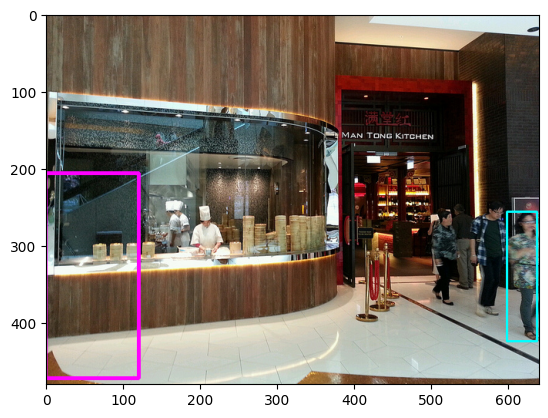

nose	([76.0, 66.0])	vis(1)
L-eye	([81.0, 62.0])	vis(1)
R-eye	([73.0, 63.0])	vis(1)
L-ear	([89.0, 64.0])	vis(1)
R-ear	([0.0, 0.0])	vis(0)
L-shder	([99.0, 81.0])	vis(1)
R-shder	([0.0, 0.0])	vis(0)
L-elb	([107.0, 103.0])	vis(1)
R-elb	([0.0, 0.0])	vis(0)
L-wrst	([88.0, 98.0])	vis(1)
R-wrst	([0.0, 0.0])	vis(0)
L-hip	([96.0, 117.0])	vis(1)
R-hip	([0.0, 0.0])	vis(0)
L-knee	([96.0, 157.0])	vis(1)
R-knee	([0.0, 0.0])	vis(0)
L-ankl	([99.0, 193.0])	vis(1)
R-ankl	([0.0, 0.0])	vis(0)

### pose.dataset ###


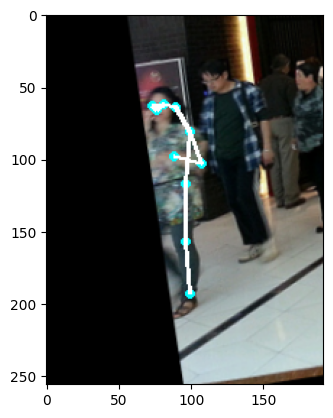


### hrnet.dataset ###


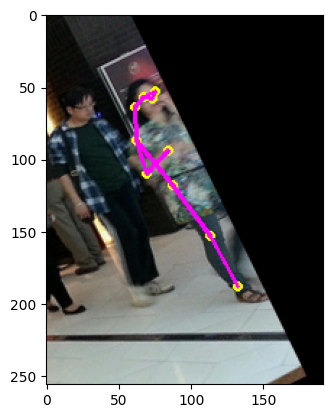


pose.dataset.idx(anno_id): 16(1294045)


In [26]:
half_body, hflip, rotate, scale = randomly_select_args()

#half_body = False
#hflip = False
#rotate = 30
#scale = 1.25

print(f"half_body:({half_body}), hflip:({hflip}), rotate:({rotate}), scale:({scale})")

check(idx=118688, half_body=half_body, hflip=hflip, rotate=rotate, scale=scale, verbose=True)